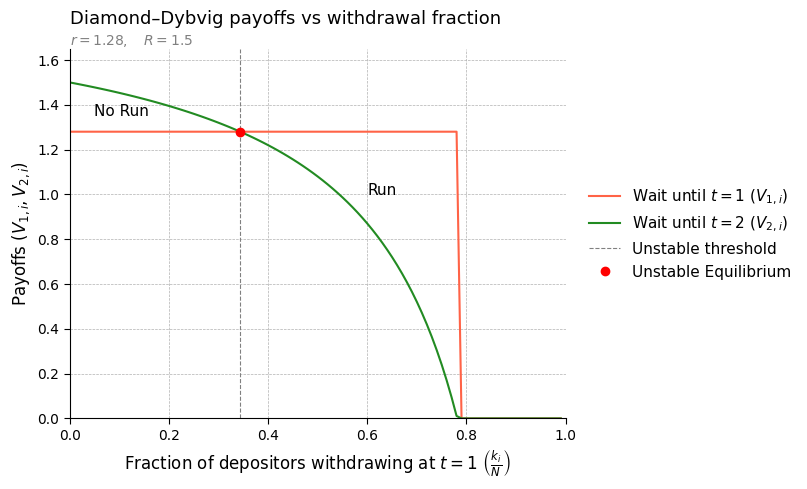

In [82]:
import numpy as np
import matplotlib.pyplot as plt

def g(x, R, r):
    """
    g(x) = max(R(1-rx)/(1-x), 0)
    """
    with np.errstate(divide="ignore", invalid="ignore"):
        value = R * (1 - r * x) / (1 - x)

    return np.where(value >= 0, value, 0.0)


def f(x, r):
    """
    f(x) = r,  if x <= 1/r
           0,  if x > 1/r
    """
    return np.where(x <= 1 / r, r, 0.0)


x = np.arange(0, 1, 0.01)

R = 1.5
r = 1.28
Lam = 0.25

EW = (R-r)/(r*(R-1))

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

# Plot
plt.plot(x, f(x, r), c='tomato', label = r'Wait until $t = 1$ $\left(V_{1,i}\right)$')
plt.plot(x, g(x, R, r), c='forestgreen', label = r'Wait until $t = 2$ $\left(V_{2,i}\right)$')
plt.vlines(
    x=EW,
    ymin=0,
    ymax=g(0, R, r)*1.1,
    ls='dashed',
    color='grey',
    lw=0.8, label = 'Unstable threshold'
)

plt.plot(EW, r, 'ro', label = 'Unstable Equilibrium')

plt.xlim(0, 1)
plt.ylim(0, g(0, R, r)*1.1)

plt.xlabel(r'Fraction of depositors withdrawing at $t = 1$ $\left(\frac{k_i}{N}\right)$')
plt.ylabel(r'Payoffs $\left(V_{1,i}, V_{2,i}\right)$')


plt.grid(ls='dashed', lw=0.5)

# Get axes
ax = plt.gca()

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep left and bottom axes
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Make axes/ticks similar to R
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

# Main title
ax.set_title(
    "Diamond–Dybvig payoffs vs withdrawal fraction",
    loc="left",
    fontsize=13,
    pad=18
)

# Subtitle
ax.text(
    0, 1,
    r"$r = 1.28,\quad R = 1.5$",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="bottom",
    color="gray"
)

ax.tick_params(
    axis='both',
    direction='out',
    length=4,
    width=0.8
)

plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

plt.text(
    0.05, 1.35,
    "No Run",
    fontsize=11,
    color="black"
)

plt.text(
    0.6, 1,
    "Run",
    fontsize=11,
    color="black"
)

#plt.savefig( 'outputs/DD/FIG1.png', dpi=300, bbox_inches='tight' )


plt.show()

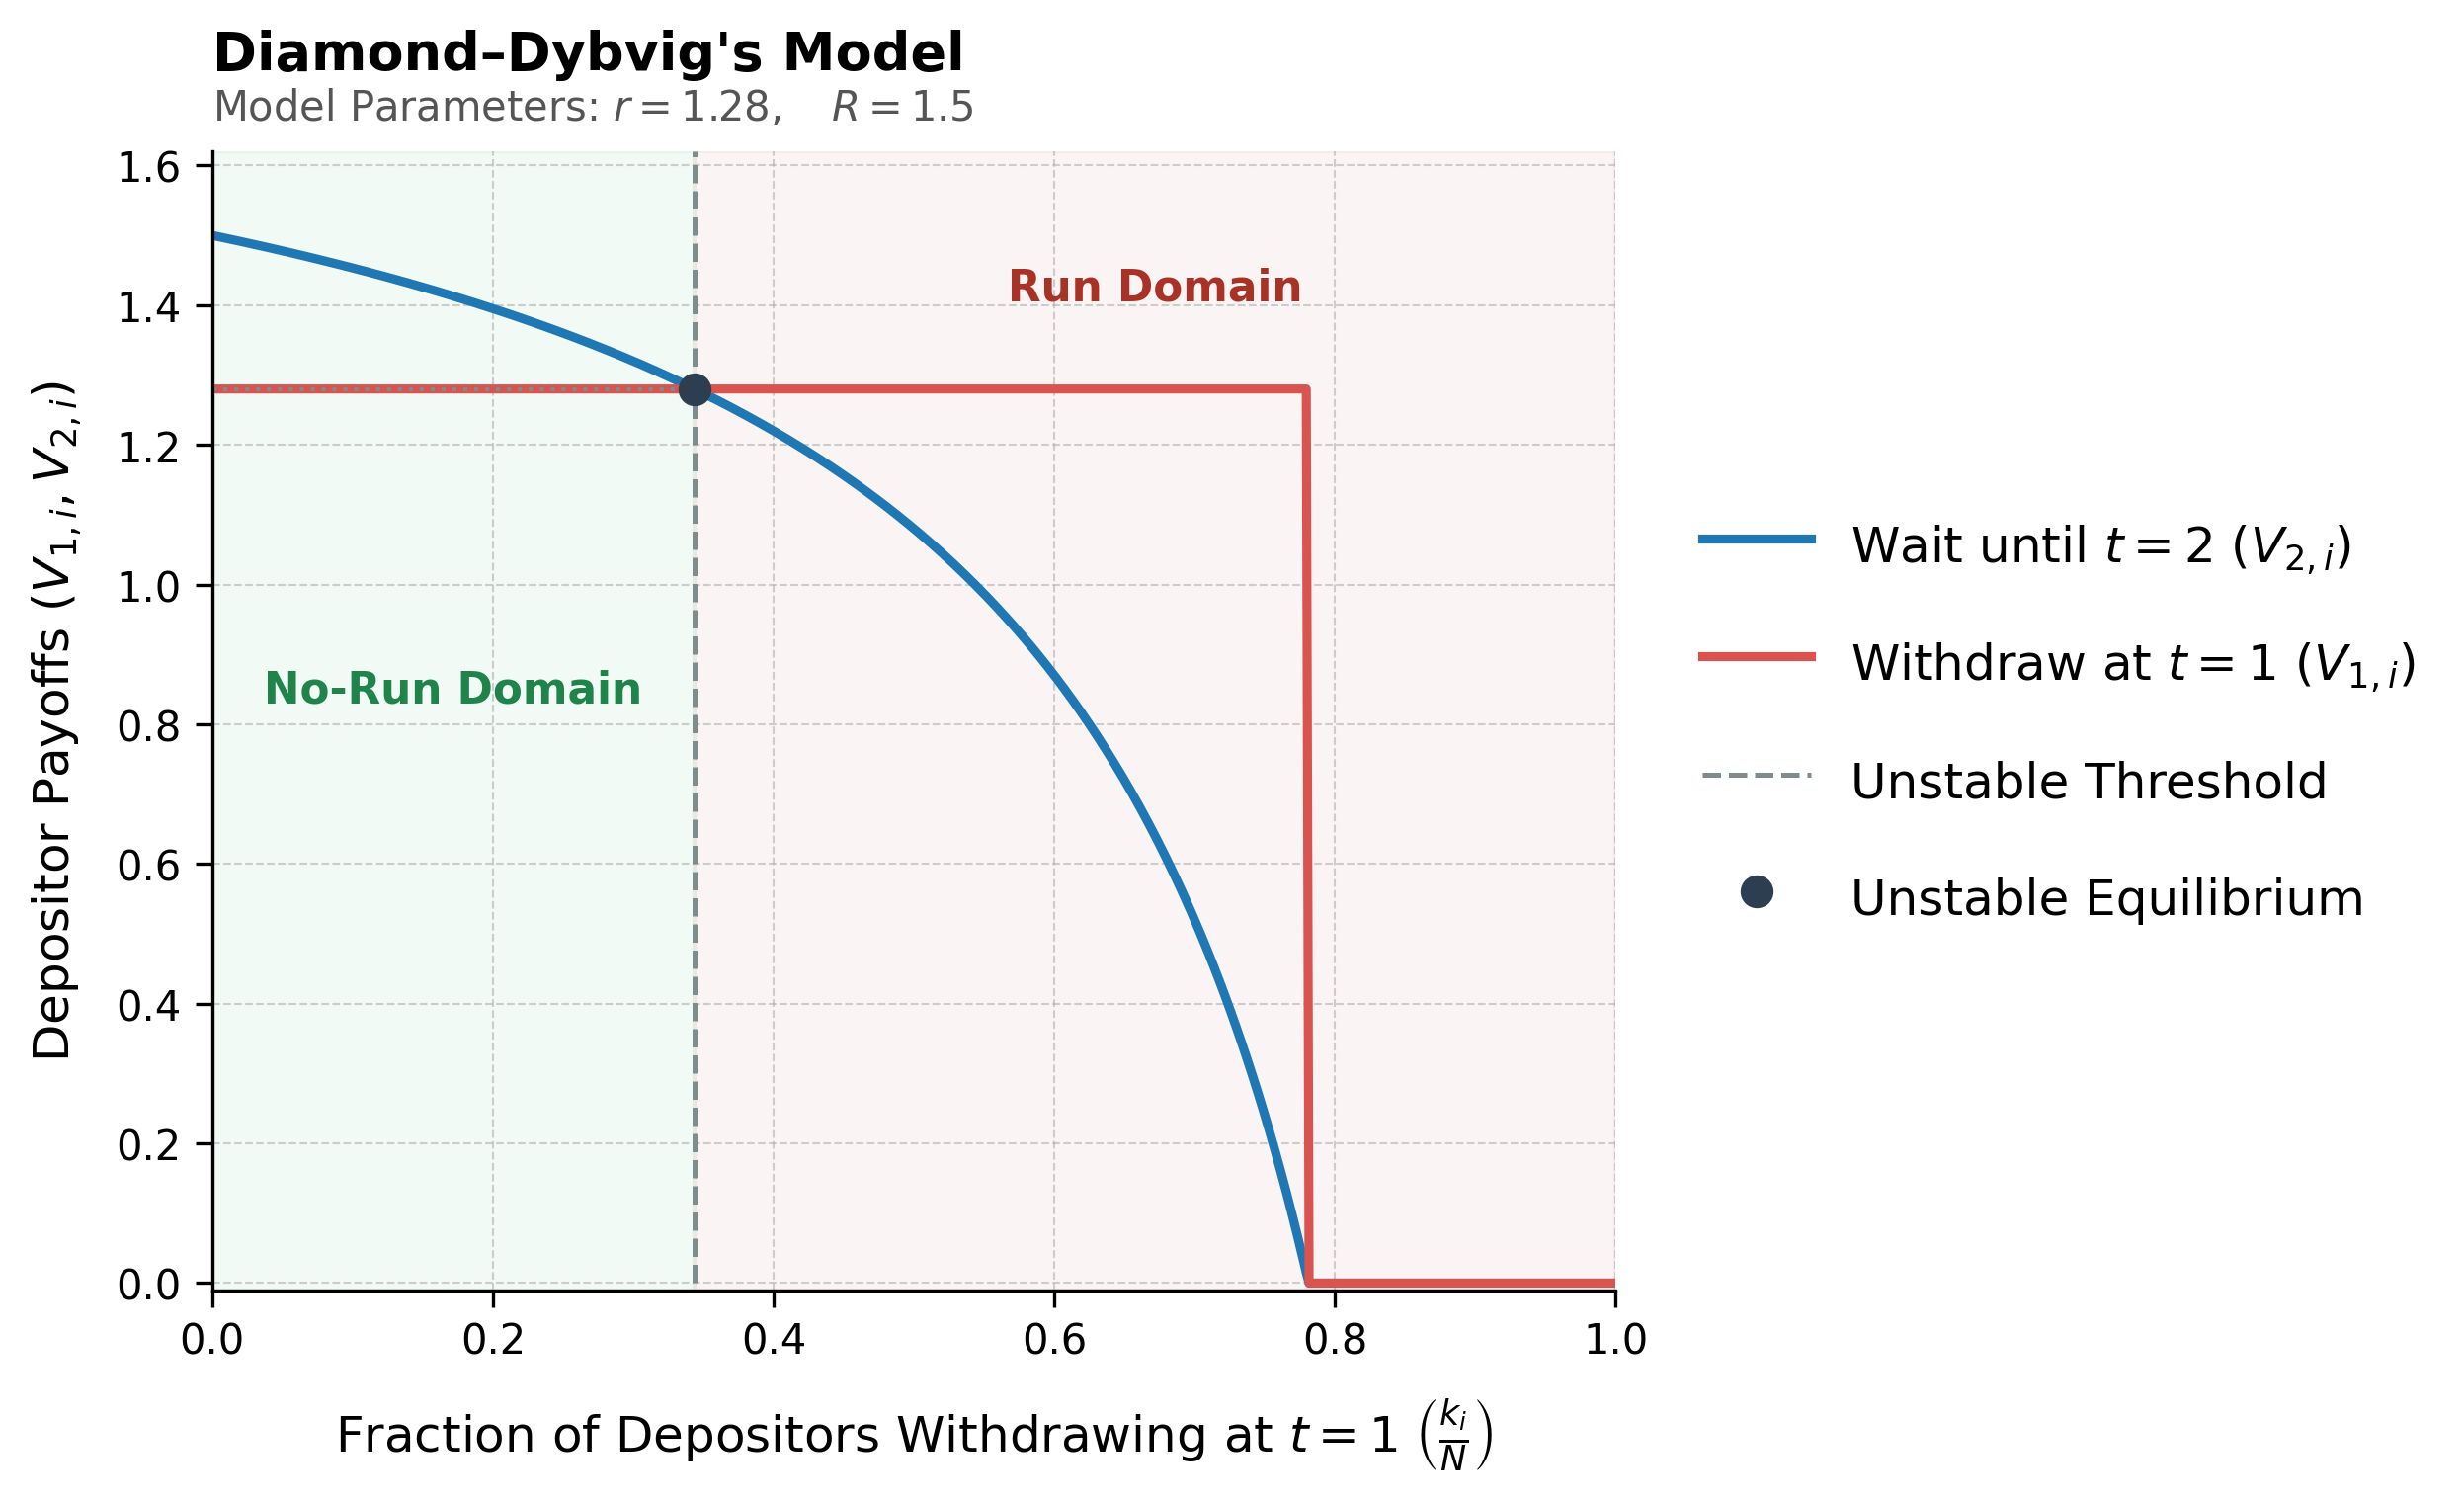

In [108]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Model Functions & Parameters
# -------------------------------------------------
R = 1.5
r = 1.28

# Unstable equilibrium threshold: x* = (R - r) / [r(R - 1)]
EW = (R - r) / (r * (R - 1))

def g(x, R, r):
    """Payoff for waiting until t = 2: V_{2,i} = max(R*(1 - r*x)/(1 - x), 0)"""
    with np.errstate(divide="ignore", invalid="ignore"):
        val = R * (1 - r * x) / (1 - x)
    return np.where(x <= 1 / r, val, 0.0)

def f(x, r):
    """Payoff for withdrawing at t = 1: V_{1,i} = r for x <= 1/r else 0"""
    return np.where(x <= 1 / r, r, 0.0)

# Dense grid strictly up to the bank depletion threshold x = 1/r
x = np.linspace(0, 1, 500)

# -------------------------------------------------
# 2. Style & Canvas Configuration
# -------------------------------------------------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

fig, ax = plt.subplots(figsize=(8.5, 5.2), dpi=300)

# Color Palette
COLOR_V1 = "#D9534F"      # Soft Crimson (t = 1)
COLOR_V2 = "#1F78B4"      # Deep Blue (t = 2)
COLOR_EQ = "#2C3E50"      # Dark Slate for Equilibrium
COLOR_REF = "#7F8C8D"     # Muted Gray for reference lines

# -------------------------------------------------
# 3. Curves & Threshold Lines
# -------------------------------------------------
# Payoff curves
ax.plot(x, g(x, R, r), color=COLOR_V2, lw=2.2, label=r'Wait until $t=2$ ($V_{2,i}$)')
ax.plot(x, f(x, r), color=COLOR_V1, lw=2.2, label=r'Withdraw at $t=1$ ($V_{1,i}$)')
# Maximum Y-limit for plotting
y_max = g(0, R, r) * 1.08

# Vertical threshold line x*
ax.vlines(
    x=EW, ymin=0, ymax=y_max,
    colors=COLOR_REF, linestyles='dashed', lw=1.2,
    label=r'Unstable Threshold'
)

# Horizontal reference line at y = r
ax.hlines(
    y=r, xmin=0, xmax=EW,
    colors=COLOR_REF, linestyles='dotted', lw=1.0
)

# Highlight Equilibrium Point
ax.plot(EW, r, 'o', color=COLOR_EQ, markersize=7, zorder=5, label = 'Unstable Equilibrium')

# -------------------------------------------------
# 4. Annotations & Shading
# -------------------------------------------------
# Region background shading (No Run vs Run)
ax.axvspan(0, EW, color="#27AE60", alpha=0.06, label="_nolegend_")
ax.axvspan(EW, 1.0, color="#C0392B", alpha=0.05, label="_nolegend_")

# Region text labels
ax.text(
    EW / 2, 0.85, "No-Run Domain",
    fontsize=10.5, color="#1E8449", fontweight="bold", ha="center", va="center"
)
ax.text(
    (EW + 1.0) / 2, y_max * 0.88, "Run Domain",
    fontsize=10.5, color="#A93226", fontweight="bold", ha="center", va="center"
)

# Point annotation for unstable equilibrium

# -------------------------------------------------
# 5. Axes & Formatting
# -------------------------------------------------
ax.set_xlim(0, 1.0)
ax.set_ylim(-0.01, y_max)

ax.set_xlabel(r'Fraction of Depositors Withdrawing at $t=1$ $\left(\frac{k_i}{N}\right)$', labelpad=8)
ax.set_ylabel(r'Depositor Payoffs ($V_{1,i}, V_{2,i}$)', labelpad=8)

# Title & Subtitle
ax.set_title("Diamond–Dybvig's Model", loc="left", fontweight="bold", pad=20)
ax.text(
    0, 1.02, r"Model Parameters: $r = 1.28,\quad R = 1.5$",
    transform=ax.transAxes, fontsize=10, ha="left", va="bottom", color="#555555"
)

# Spine formatting
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

ax.tick_params(axis='both', direction='out', length=4, width=0.8)
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)

# -------------------------------------------------
# 6. Enlarged Legend (Positioned Right, No Frame)
# -------------------------------------------------
ax.legend(
    loc='center left',
    bbox_to_anchor=(1.03, 0.5),
    ncol=1,
    frameon=False,
    fontsize=12,
    labelspacing=1.2,
    handlelength=2.2,
    handleheight=1.4
)

plt.tight_layout()

# Save publication-quality figures
plt.savefig('outputs/DD/FIG1.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

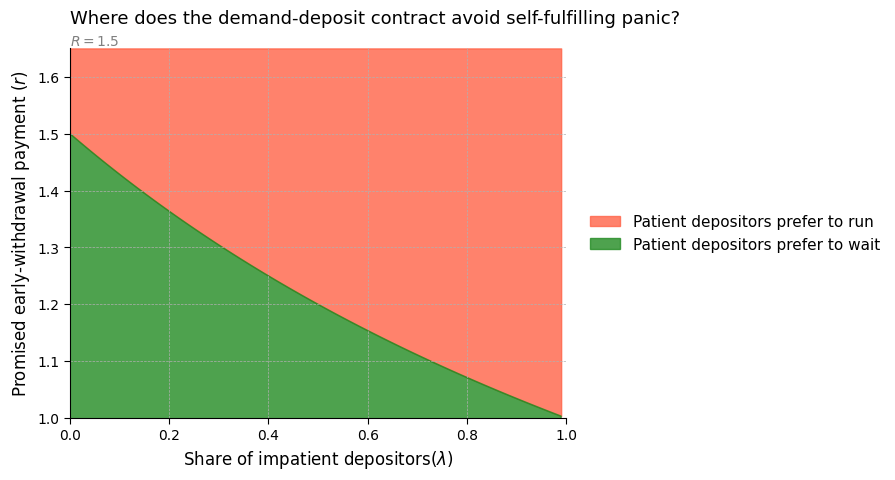

In [84]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0, 1, 0.01)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

# Plot
y_curve = R / (1 + (R - 1) * x)

plt.fill_between(
    x, y_curve, g(0, R, r)*1.1,
    color='tomato',
    alpha = 0.8,
    label='Patient depositors prefer to run'
)

plt.fill_between(
    x, 0, y_curve,
    color='forestgreen',
    label='Patient depositors prefer to wait',
    alpha = 0.8
)


plt.xlim(0, 1)
plt.ylim(1, R*1.1)

plt.xlabel(r'Share of impatient depositors($\lambda$)')
plt.ylabel(r'Promised early-withdrawal payment ($r$)')


plt.grid(ls='dashed', lw=0.5)

# Get axes
ax = plt.gca()

ax.set_title(
    "Where does the demand-deposit contract avoid self-fulfilling panic?",
    loc="left",
    fontsize=13,
    pad=18
)

# Subtitle
ax.text(
    0, 1,
    r"$R = 1.5$",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="bottom",
    color="gray"
)

ax.tick_params(
    axis='both',
    direction='out',
    length=4,
    width=0.8
)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep left and bottom axes
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Make axes/ticks similar to R
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

ax.tick_params(
    axis='both',
    direction='out',
    length=4,
    width=0.8
)

plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

plt.savefig( 'outputs/DD/FIG2.png', dpi=300, bbox_inches='tight' )

plt.show()

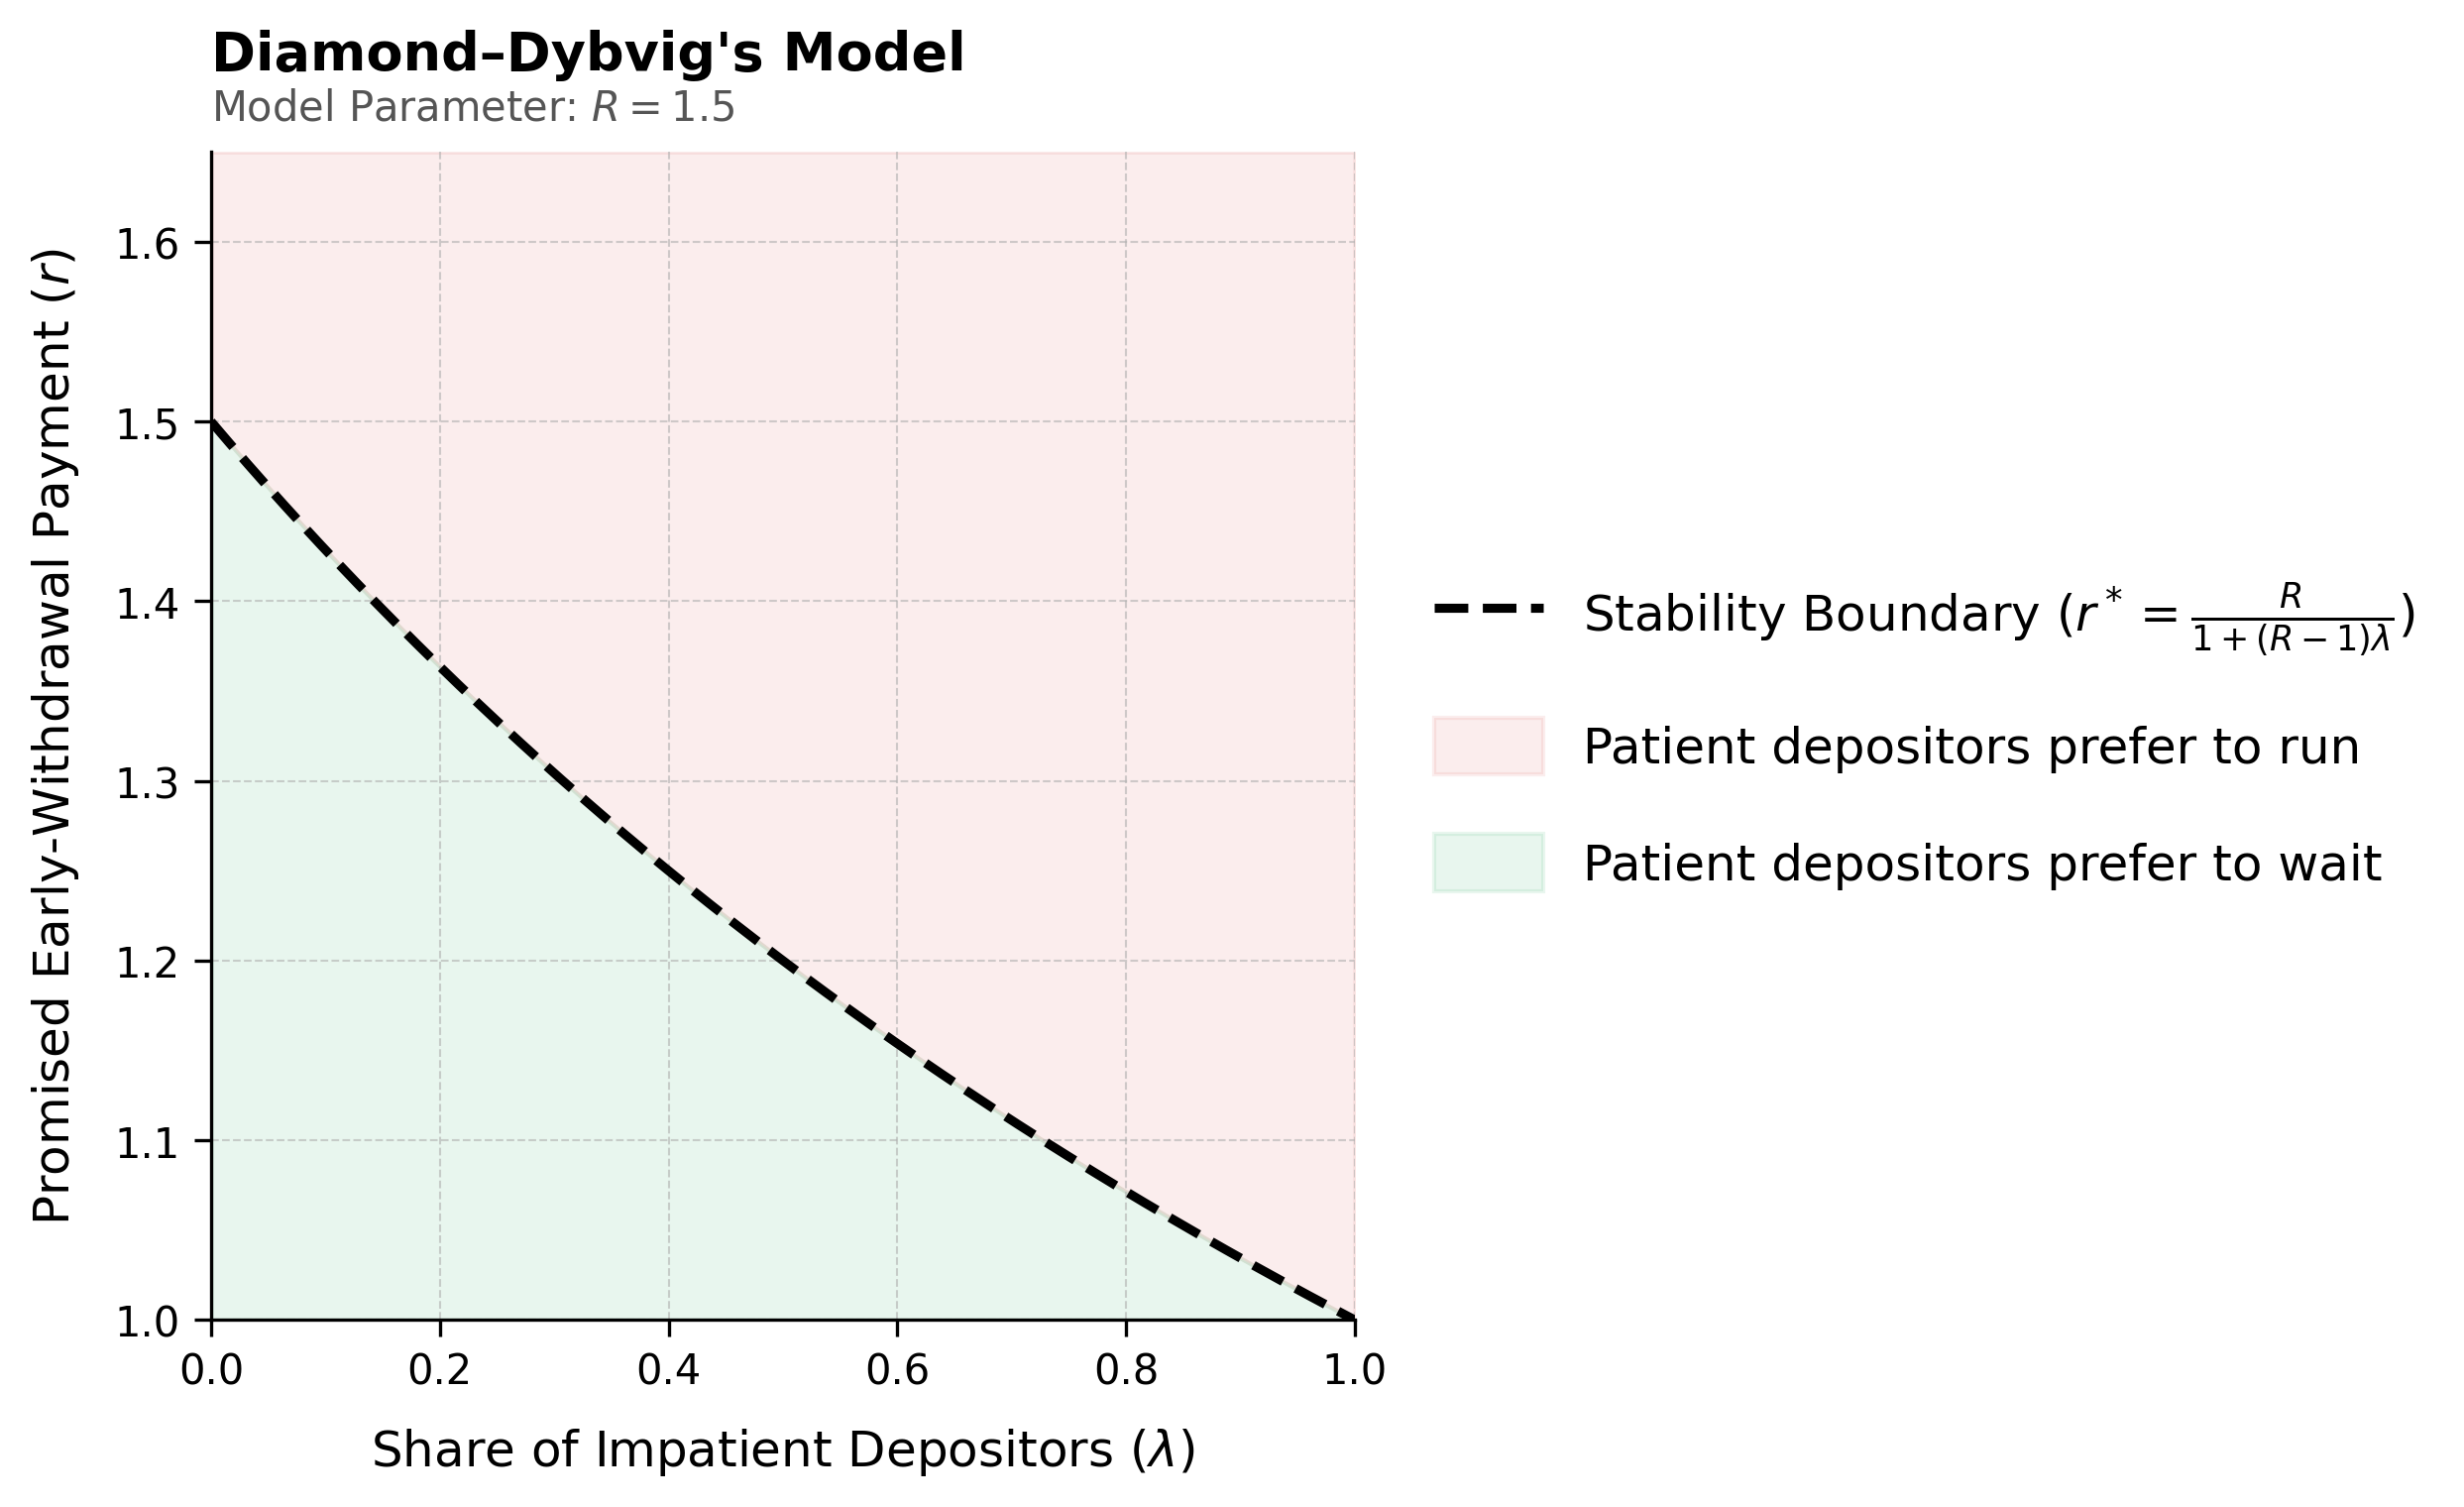

In [109]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Model Parameters & Functions
# -------------------------------------------------
R = 1.5
x = np.linspace(0, 1, 500)

# Critical boundary curve: r = R / [1 + (R - 1) * lambda]
y_curve = R / (1 + (R - 1) * x)

# Upper bound for Y-axis fill
y_max = R * 1.1

# -------------------------------------------------
# 2. Canvas & Style Configuration
# -------------------------------------------------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

fig, ax = plt.subplots(figsize=(8.5, 5.2), dpi=300)

# Academic Color Palette
COLOR_RUN = "#D9534F"       # Pastel Crimson
COLOR_NO_RUN = "#27AE60"    # Emerald Green
COLOR_LINE = "#1F78B4"      # Deep Blue for boundary curve

# -------------------------------------------------
# 3. Shading & Boundary Plotting
# -------------------------------------------------
# Boundary Curve
ax.plot(
    x, y_curve,
    color='black',
    ls = 'dashed',
    lw=2.2,
    label=r'Stability Boundary ($r^* = \frac{R}{1 + (R-1)\lambda}$)'
)

# Shaded Region: Run Domain (Patient depositors prefer to run)
ax.fill_between(
    x, y_curve, y_max,
    color=COLOR_RUN,
    alpha=0.1,
    label='Patient depositors prefer to run'
)

# Shaded Region: No-Run Domain (Patient depositors prefer to wait)
ax.fill_between(
    x, 1.0, y_curve,
    color=COLOR_NO_RUN,
    alpha=0.1,
    label='Patient depositors prefer to wait'
)


# -------------------------------------------------
# 5. Axes & Formatting
# -------------------------------------------------
ax.set_xlim(0, 1.0)
ax.set_ylim(1.0, y_max)

ax.set_xlabel(r'Share of Impatient Depositors ($\lambda$)', labelpad=8)
ax.set_ylabel(r'Promised Early-Withdrawal Payment ($r$)', labelpad=8)

# Title & Subtitle
ax.set_title("Diamond–Dybvig's Model", loc="left", fontweight="bold", pad=20)
ax.text(
    0, 1.02, r"Model Parameter: $R = 1.5$",
    transform=ax.transAxes, fontsize=10, ha="left", va="bottom", color="#555555"
)

# Spine & Grid formatting
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

ax.tick_params(axis='both', direction='out', length=4, width=0.8)
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)

# -------------------------------------------------
# 6. Enlarged Legend (Positioned Right, No Frame)
# -------------------------------------------------
ax.legend(
    loc='center left',
    bbox_to_anchor=(1.03, 0.5),
    ncol=1,
    frameon=False,
    fontsize=12,
    labelspacing=1.2,
    handlelength=2.2,
    handleheight=1.4
)

plt.tight_layout()

# Save publication-quality figures
plt.savefig('outputs/DD/FIG2.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()